# 08 课程预览、审核发布与分布式事务


## 资料来源与当天目标

本篇对应百度网盘 14 天规划中的 **day08 课程发布 分布式事务**。第 07 篇完成了视频处理、媒资绑定与门户部署；今天继续把课程从“能够编辑、预览”推进到“提交审核、保存发布快照、创建后台同步任务”。

主要资料及核对范围：

- `第4章 课程发布v3.1.docx`：课程发布整体流程、2.4—2.5 课程预览与播放、3 课程审核、4.1—4.4 课程发布和消息 SDK。2.2—2.3 的 FreeMarker 与门户部署只作必要衔接。
- day08 `代码/xuecheng-plus-project.zip`：已取得本地代码包，重点核对内容服务 Controller、DTO、预发布/发布 PO、`CoursePublishServiceImpl`、`CoursePublishTask`、消息 SDK、启动类和 Maven 依赖。
- `xuecheng-plus-message-sdk.zip`：核对消息增删改查、分片 SQL、多线程处理、阶段状态与归档逻辑；它与 day08 项目包中的 SDK 主源码一致。
- `course_template.ftl` 与项目内同名模板：两份文件字节不同，关键模型字段、课程计划循环、预览链接及图片路径一致；本篇以项目内模板解释实际调用。
- 前面已下载的 `nacos_config_export.zip`：核对内容服务入口及 FreeMarker 配置。不同资料的 namespace、数据库名有差异，不能直接混用环境配置。

**阅读约定：**“源码”指本次读取的 day08 代码；“讲义”指上述 v3.1 文档；“校正/补充”是为说明正确行为而整理的建议，不能当作原项目已有功能。本篇代码块以核心片段为主，沿用项目中已有的 PO、Mapper、Service 和异常类。

**本日边界：**day09 的目录是“页面静态化 认证授权 SpringSecurity”。本篇解释 HTML、搜索索引、缓存的同步目标，完成消息任务框架的学习；实际静态页面生成上传、完整搜索和缓存实现留待后续。下文联调步骤是供学习时执行的清单，本次未启动项目、执行课程 SQL 或运行 SDK 测试。

当天应能回答：审核为什么要保存快照；发布为什么不能直接使用最新草稿；`@Transactional` 能保证哪些写入；本地消息表怎样减少任务丢失；阶段状态为什么仍需要目标写入幂等；调度成功与业务同步成功有什么区别。


## 1. 从课程编辑到发布的整体流程

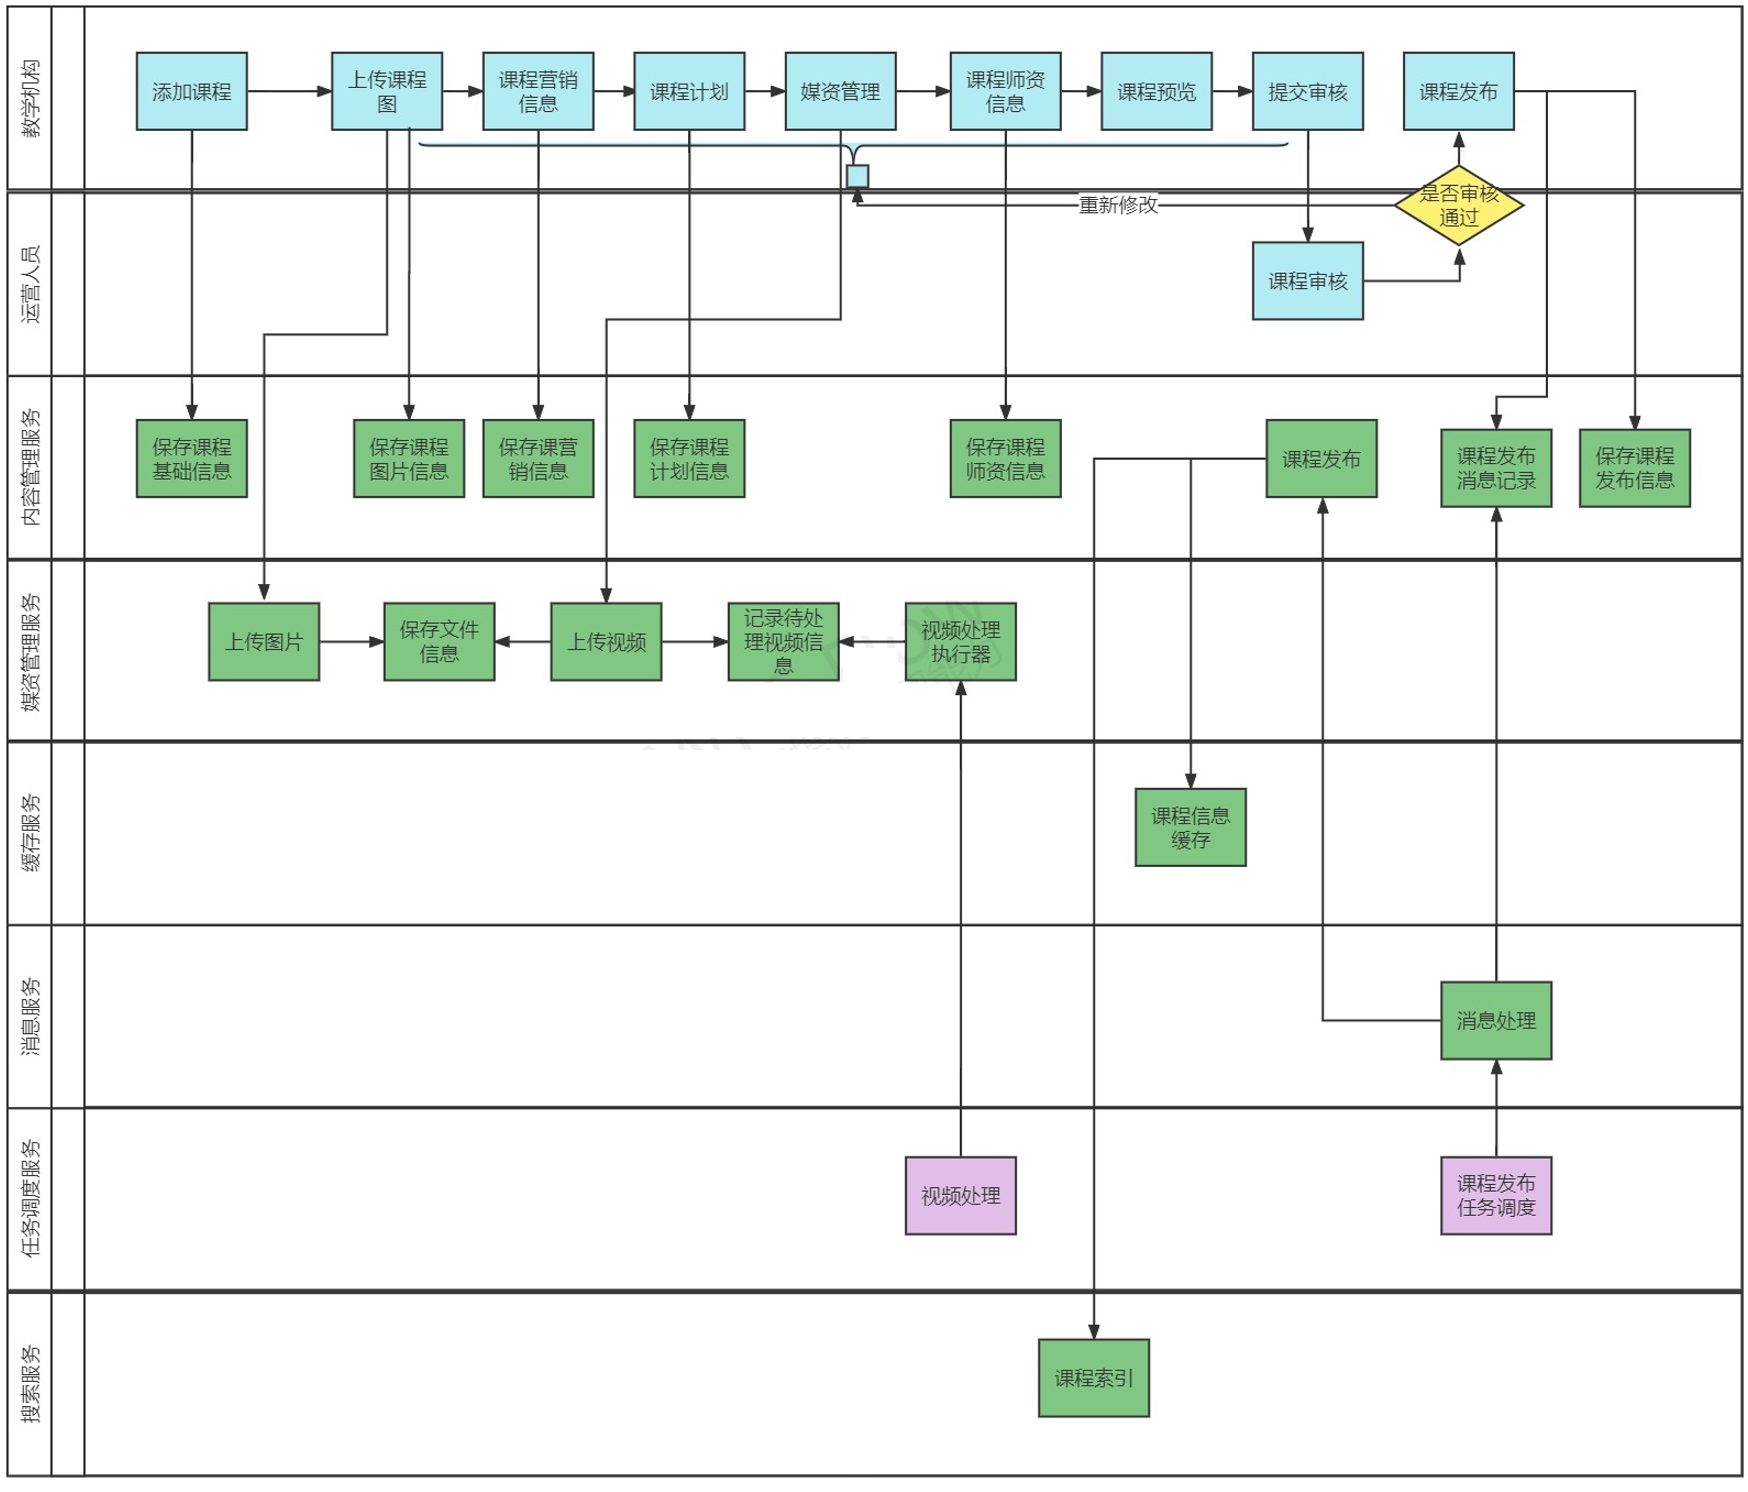

教学机构负责编辑课程与提交审核，运营人员审核提交时的内容；通过审核后，机构发起发布，后台再把发布数据同步到页面、搜索和缓存。

```text
编辑课程基本信息、营销信息、计划、媒资关系
       ↓
预览课程详情与视频播放
       ↓
提交审核 → 保存 course_publish_pre 快照 → 等待运营审核
       ↓                                        ↓
可继续编辑草稿                           审核通过 / 不通过
                                                ↓
发布已通过的快照 → 保存 course_publish + mq_message
                                                ↓
XXL-JOB 扫描消息 → 执行各同步阶段 → 成功消息归档
```

“预览”“审核通过”“发布事务提交”“所有派生数据就绪”是四个不同节点。预览只能说明页面和播放链路基本可用；审核通过表示这个版本获准发布；数据库发布成功后，后台同步还可能正在执行。

课程还有上下架、重新审核和重新发布的业务设计。day08 没有实现完整运营审核和上下架系统，不能仅凭流程图就认为这些接口已经齐全。


## 2. 动态预览与正式静态页面

课程预览使用 **FreeMarker 模板 + 当前课程数据 → HTML**。机构修改草稿后再次预览，就能看到当前编辑结果。这适合验证排版、课程介绍、目录和绑定视频。

正式页面的目标是把已审核的发布快照渲染成 HTML，上传到文件系统后供浏览器访问。它减少每次浏览时的数据库查询，也便于缓存，但需要处理发布后更新、版本切换和下架。

| 对比项 | 动态课程预览 | 后续正式静态页面 |
| --- | --- | --- |
| 数据来源 | 当前基础、营销、课程计划等编辑数据 | 已审核的发布快照 |
| 渲染时机 | 请求预览时 | 后台发布任务执行时 |
| 返回内容 | 服务端渲染的 HTML | 已保存的 HTML 文件 |
| 更新方式 | 修改草稿后重新请求 | 重新发布并同步新版本 |
| 本日进度 | 预览接口与模板已提供 | 任务阶段仍为演示框架 |

动态模板也会输出 HTML，所以不能把“返回 HTML”和“已经完成页面静态化”画等号。判断静态化要看：是否真正生成文件、是否上传成功、正式入口是否能读取该文件。


## 3. FreeMarker 接入与配置衔接

内容 API 工程引入 FreeMarker Starter，模板放在 `src/main/resources/templates/course_template.ftl`。视图名称为 `course_template`，由配置补上 `.ftl` 后缀。

```xml
<dependencies>
    <dependency>
        <groupId>org.springframework.boot</groupId>
        <artifactId>spring-boot-starter-freemarker</artifactId>
    </dependency>
</dependencies>
```

项目的 `bootstrap.yml` 在 Nacos 共享配置中引用 `freemarker-config-dev.yaml`，组为 `xuecheng-plus-common`。开发阶段可使用：

```yaml
spring:
  freemarker:
    enabled: true
    cache: false
    settings:
      template_update_delay: 0
    suffix: .ftl
    charset: UTF-8
    template-loader-path: classpath:/templates/
```

关闭模板缓存便于开发，不宜照搬为生产性能策略。修改 `src/main/resources` 后，要让 IDE 编译/构建把文件复制进运行 classpath；浏览器刷新不会自动完成资源复制。

**配置校正：**下载的共享 YAML 把 `resources.add-mappings` 写在了 `spring.freemarker` 下，它不能因此控制 Spring MVC 的静态资源映射。项目父 POM 使用 Spring Boot `2.3.7.RELEASE`，若确实要关闭应用内静态资源映射，对应写法为：

```yaml
spring:
  resources:
    add-mappings: false
```

门户样式、脚本由 Nginx 提供，关闭内容 API 的静态资源映射并不等于关闭门户资源。升级 Spring Boot 后应重新核对配置项，不直接沿用旧版本键名。


## 4. 课程预览需要聚合哪些数据

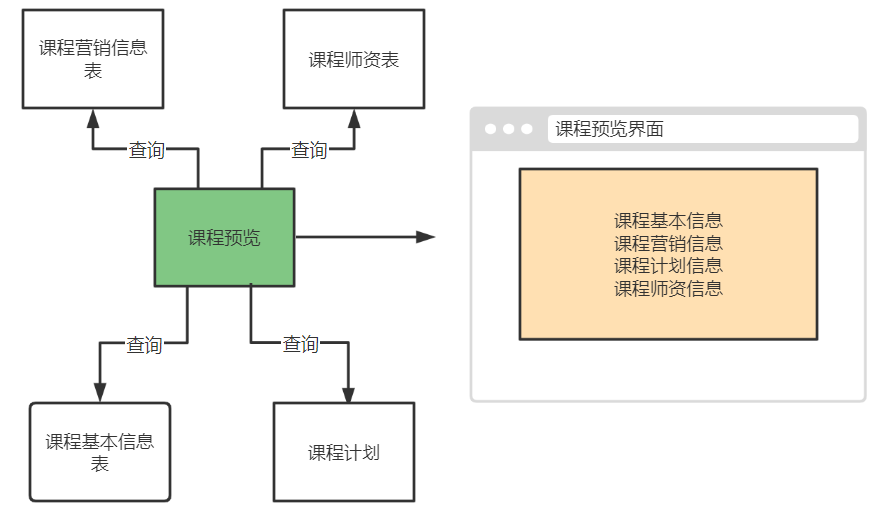

项目定义 `CoursePreviewDto`，把模板需要的数据组织在一个模型中：

```java
@Data
public class CoursePreviewDto {
    // 课程基本信息及营销信息。
    private CourseBaseInfoDto courseBase;

    // 课程计划树，小节中包含绑定媒资关系。
    private List<TeachplanDto> teachplans;
}
```

`TeachplanDto` 继承 `Teachplan`，还有两个关键属性：

```java
private TeachplanMedia teachplanMedia;
private List<TeachplanDto> teachPlanTreeNodes;
```

服务层的实际聚合流程是：

```java
@Override
public CoursePreviewDto getCoursePreviewInfo(Long courseId) {
    CoursePreviewDto result = new CoursePreviewDto();
    result.setCourseBase(
            courseBaseInfoService.getCourseBaseInfo(courseId));
    result.setTeachplans(
            teachplanService.findTeachplanTree(courseId));
    return result;
}
```

`courseBase` 中包含课程名称、分类名称、图片、收费方式、价格等；`teachplans` 是“大章 → 小节”的树，小节通过 `teachplanMedia` 提供媒资关系。讲义图画有教师信息，但本次 DTO 里师资仅为注释，尚未完整聚合。

**源码边界：**基础查询在课程不存在时返回 `null`，预览聚合方法没有拒绝这个结果，后续模板访问 `model.courseBase.name` 会失败。应先处理“课程不存在”和“无权限访问”，再开始渲染；分类记录为空、营销数据缺失等问题也应给出明确业务反馈。


## 5. 把模型放进课程模板

控制器将 DTO 以 `model` 为名称放入模型，所以模板使用 `${model.courseBase.name}`，而不是 `${courseBase.name}`。

```ftl
<h1>${model.courseBase.name}</h1>
<p>${model.courseBase.mtName!''} / ${model.courseBase.stName!''}</p>

<#if model.courseBase.charge == '201000'>
  <span>免费</span>
<#else>
  <span>价格：${model.courseBase.price!''}</span>
</#if>

<#if model.courseBase.pic??>
  <img src="http://file.51xuecheng.cn${model.courseBase.pic}" alt="课程封面">
</#if>

<#list model.teachplans as firstNode>
  <h2>${firstNode.pname}</h2>
  <#list firstNode.teachPlanTreeNodes as secondNode>
    <p>${secondNode.pname}</p>
  </#list>
</#list>
```

模板还按 `204001/204002/204003` 显示等级，按 `200002/200003` 显示教学模式；它们属于不同字典，不能与审核/发布状态混用。图片地址由文件服务域名拼接 `pic` 路径，因此数据里的路径和 Nginx 文件代理必须一致。

小节学习入口的 `chapter` 参数取自 `teachplanMedia.teachplanId`。它是课程计划 ID，后续前端还要从绑定关系找到 `mediaId`，不能拿 `chapter` 直接当媒资文件 ID。

**空值补充：**`x!''` 提供默认值，`x??` 检查存在性。深层表达式需要保护中间对象，例如：

```ftl
<#list (model.teachplans)![] as firstNode>
  <#list (firstNode.teachPlanTreeNodes)![] as secondNode>
    <#if secondNode.teachplanMedia??>
      <a href="/course/preview/learning.html?id=${model.courseBase.id}&amp;chapter=${(secondNode.teachplanMedia.teachplanId)!''}">
        ${secondNode.pname}
      </a>
    <#else>
      <span>${secondNode.pname}（未绑定视频）</span>
    </#if>
  </#list>
</#list>
```

**输出安全补充：**源模板未声明这里展示的自动 HTML 转义策略。普通课程名称、标签和用户输入应进行上下文合适的转义；可在适用模板中明确 HTML 输出格式：

```ftl
<#ftl output_format="HTML" auto_esc=true>
<p>${(model.courseBase.description)!''}</p>
```

HTML 转义会把富文本标签显示为文本；允许富文本时应先做可信的 HTML 清洗，再按明确边界输出。不要为了显示富文本而给所有字段加 `?no_esc`。源模板还把课程值放入 JavaScript 字符串，那里需要 JavaScript/JSON 的编码方式，单靠 HTML 转义不够。


## 6. 课程预览接口：返回视图而不是 JSON

项目用同一个 `CoursePublishController` 承担预览、提交审核和发布。预览方法返回 `ModelAndView`，类上使用 `@Controller`：

```java
@Controller
public class CoursePublishController {
    @Autowired
    private CoursePublishService coursePublishService;

    @GetMapping("/coursepreview/{courseId}")
    public ModelAndView preview(
            @PathVariable("courseId") Long courseId) {
        CoursePreviewDto data =
                coursePublishService.getCoursePreviewInfo(courseId);
        ModelAndView view = new ModelAndView();
        view.addObject("model", data);
        view.setViewName("course_template");
        return view;
    }
}
```

这条请求经过服务层聚合、模板查找和渲染后，浏览器得到 HTML。`@RestController` 等价于类上统一启用响应体语义，不适合把这里的普通视图方法按相同方式改写。

该类的提交审核、发布方法使用 `@ResponseBody`，表示它们是接口响应，不需要视图解析。源码返回 `void`，成功响应没有 DTO 内容；不要在客户端强行把空响应解析成课程对象。

本地测试入口示例：

```http
GET http://localhost:63040/content/coursepreview/74
```

其中 `/content` 是服务 context-path，方法路径是 `/coursepreview/{courseId}`。`74` 是讲义示例，联调时应换成当前数据库真实存在的课程 ID。


## 7. 门户、Nginx、网关和内容服务怎样衔接

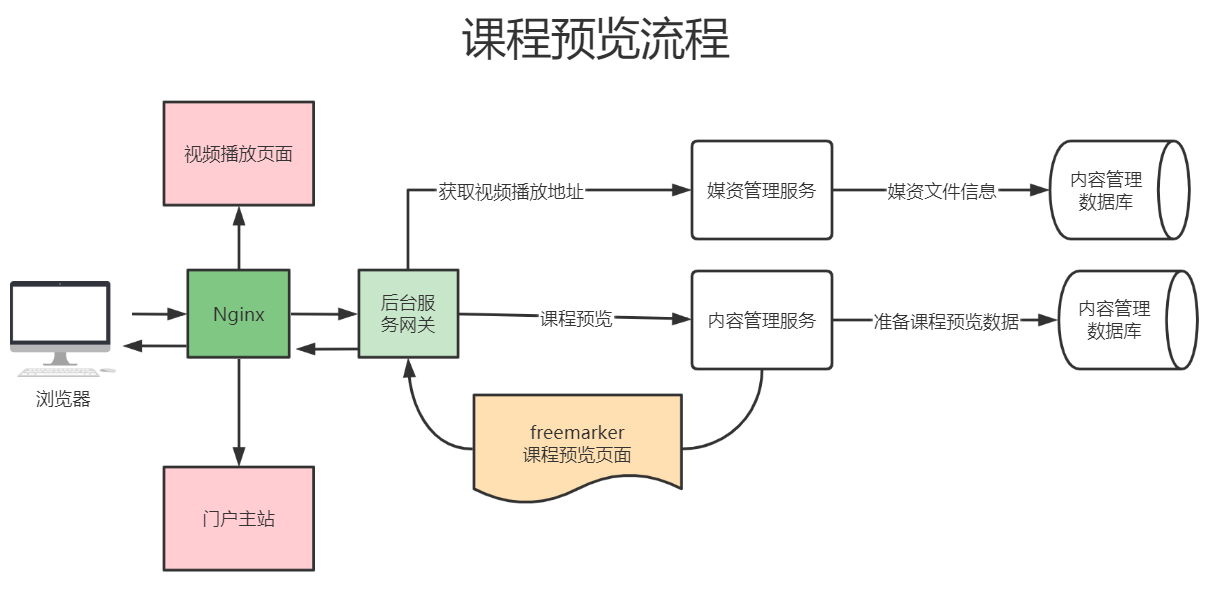

门户域名请求先到 Nginx，再经网关到内容服务。Nginx 同时还提供门户的 CSS、JavaScript 和页面资源；这些资源不会自动跟随模板一起被内容服务返回。

讲义在门户对应的 `server` 块中加入 API 代理：

```nginx
upstream gatewayserver {
    server 127.0.0.1:63010 weight=10;
}

server {
    listen 80;
    server_name www.51xuecheng.cn;

    location /api/ {
        proxy_pass http://gatewayserver/;
    }
}
```

这是代理片段，原门户的 `root`、静态资源与其他 location 仍需保留。`upstream` 放在 Nginx 的 `http` 上下文中，不能塞进 `server` 里面。

```text
浏览器：http://www.51xuecheng.cn/api/content/coursepreview/74
Nginx：把匹配到的 /api/ 替换为 proxy_pass 中的 /
网关收到：/content/coursepreview/74
内容服务：/content + /coursepreview/74
```

这里 `proxy_pass http://gatewayserver/;` **带 URI `/`**，会替换 location 的匹配前缀。第 07 篇文件代理里的 `proxy_pass http://fileserver;` 不带 URI，通常保留请求路径，二者不要混写。

同时核对 hosts、门户端口、网关路由和内容服务注册情况。Nginx 配置正确并不自动证明网关能找到服务。模板中若用了以 `/` 开头的样式路径，直接打开 `localhost:63040` 的预览可能缺样式，应从门户入口检查完整效果。


## 8. 视频预览的两个公开查询接口

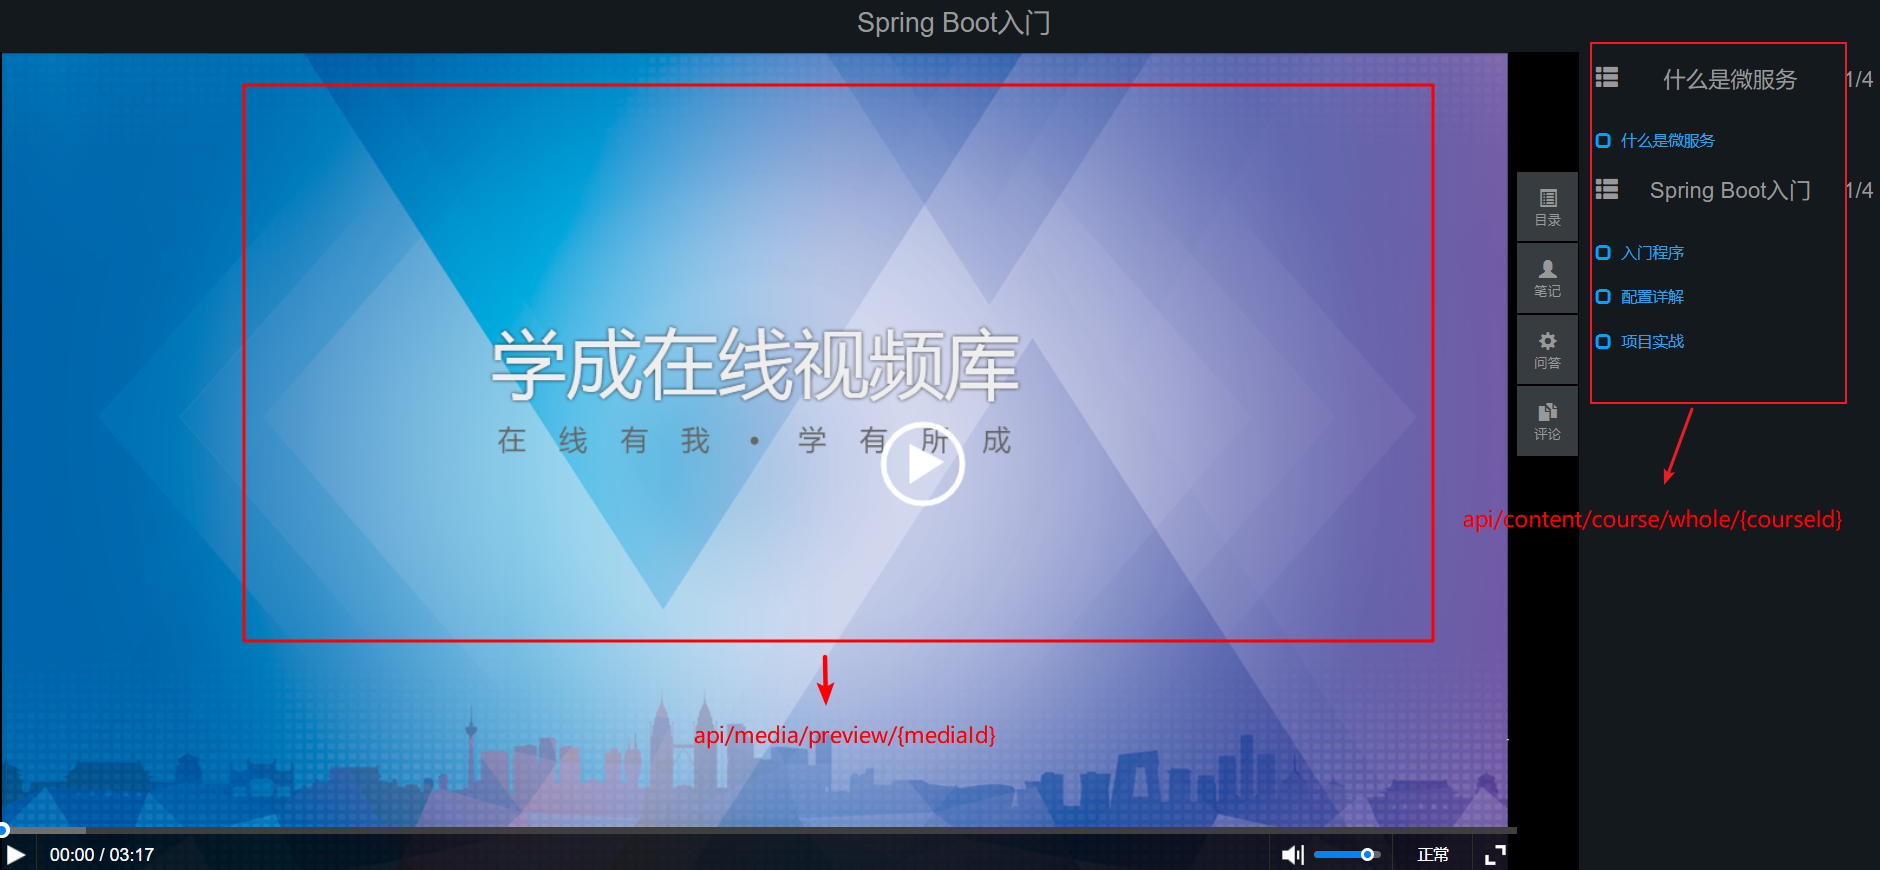

播放页通常先查课程目录和媒资绑定，再查实际视频地址：

```text
课程 ID → 查询课程整体信息 → 定位课程计划 / 小节
          → teachplanMedia.mediaId → 查询媒资 URL → 播放视频
```

内容服务的接口返回 JSON 聚合对象：

```java
@RestController
@RequestMapping("/open")
public class CourseOpenController {
    @Autowired
    private CoursePublishService coursePublishService;

    @GetMapping("/course/whole/{courseId}")
    public CoursePreviewDto getPreviewInfo(
            @PathVariable("courseId") Long courseId) {
        return coursePublishService.getCoursePreviewInfo(courseId);
    }
}
```

媒资接口核心片段按 day08 源码整理如下，所在类同样映射 `/open`：

```java
@GetMapping("/preview/{mediaId}")
public RestResponse<String> getPlayUrlByMediaId(
        @PathVariable String mediaId) {
    MediaFiles file = mediaFileService.getFileById(mediaId);
    if (file == null) {
        return RestResponse.validfail("找不到视频");
    }
    if (StringUtils.isEmpty(file.getUrl())) {
        return RestResponse.validfail("该视频正在处理中");
    }
    return RestResponse.success(file.getUrl());
}
```

**资料差异：**讲义采用抛出“视频还没有转码处理”的异常；项目源码分别返回 `validfail`。前端应按实际 `RestResponse` 状态和消息处理，不只看 HTTP 请求有没有返回。

**ID 校正：**讲义部分文字把 `mediaId` 描述为课程计划 ID，但接口实际按媒资 ID 查询 `media_files`。`courseId`、`teachplanId`、`mediaId` 是不同的标识。

**边界补充：**有 URL 只表示接口查到了地址，不证明已转码兼容、已审核或有播放权限。后续正式学习入口应校验课程发布状态和学习权限；不能因为路径叫 `/open` 就向所有人公开任意草稿和付费课程视频。


## 9. 播放接口代理与预览排错

讲义的门户代理把前端公开路径转成网关下的微服务路径：

```nginx
location /open/content/ {
    proxy_pass http://gatewayserver/content/open/;
}
location /open/media/ {
    proxy_pass http://gatewayserver/media/open/;
}
```

| 浏览器请求 | 网关收到的路径 | 服务返回 |
| --- | --- | --- |
| `/api/content/coursepreview/74` | `/content/coursepreview/74` | 课程预览 HTML |
| `/open/content/course/whole/74` | `/content/open/course/whole/74` | `CoursePreviewDto` JSON |
| `/open/media/preview/媒资ID` | `/media/open/preview/媒资ID` | 播放地址 `RestResponse` |

按层排错比一次改所有配置有效：

| 现象 | 优先检查 |
| --- | --- |
| 直接服务入口 404 | context-path、Controller 路径、服务端口 |
| 直接入口正常、门户 API 404 | Nginx URI 替换、网关路由 |
| 502 或连接失败 | 网关/服务是否启动、上游地址和监听端口 |
| 找不到模板 | `.ftl` 后缀、加载目录、运行 classpath、Nacos 共享配置 |
| 模板变量异常 | 模型名称、缺失课程/分类、树节点及媒资关系的空值 |
| 页面无样式 | 门户静态资源入口、相对路径、浏览器资源请求 |
| 查到地址仍无法播放 | MinIO 对象、Nginx 视频代理、容器/编码、HTTP Range |
| 提示处理中或找不到视频 | 是否传错 ID、视频转码结果、媒资 URL |

学习时依次观察 HTML 响应、页面资源、课程 JSON、媒资 URL 和视频网络请求。看到播放器封面不等于视频已播放，看到视频响应 200 也不等于浏览器能够解码。


## 10. 审核状态和发布状态是两条轴

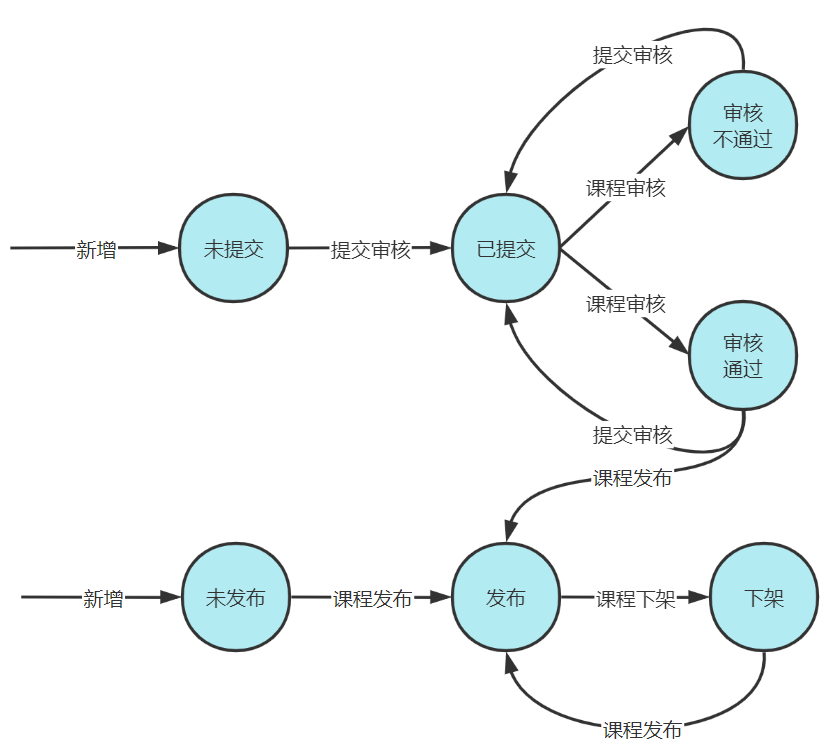

课程基础表同时有 `audit_status` 和 `status`。前者描述审核进度，后者描述发布状态；预发布表的 `status` 用作审核状态，正式发布表的 `status` 应当用发布状态。

| 字段或阶段 | 已核对状态码 | 含义 / 来源 |
| --- | --- | --- |
| `course_base.audit_status` | `202002` | 未提交；day08 新增课程源码初始化 |
| 基础表审核状态、预发布表状态 | `202003` | 已提交，等待审核 |
| 基础表审核状态、预发布表状态 | `202004` | 审核通过，允许发布 |
| `course_base.status` | `203001` | 未发布；day08 新增课程源码初始化 |
| 基础表/正式发布表的发布状态 | `203002` | 已发布；讲义的发布实现设置 |

审核不通过、下架等业务含义在流程图中存在，本篇不推测未核对的数字编码。应查环境中的数据字典再使用，尤其不要把 `202004` 复制成正式发布状态。

一门已发布课程可以继续编辑并申请新版本审核，旧发布版本不必跟着草稿立即改变。因此“草稿在待审”和“线上仍有已发布版本”可以同时成立，不能只用一个状态字段描述全部生命周期。


## 11. 为什么审核要使用预发布快照

若运营人员直接审核正在编辑的基础表、营销表和计划表，就会出现：审核员刚看完课程介绍，机构又修改了介绍或视频目录；审核通过时已经不是刚才审核的内容。

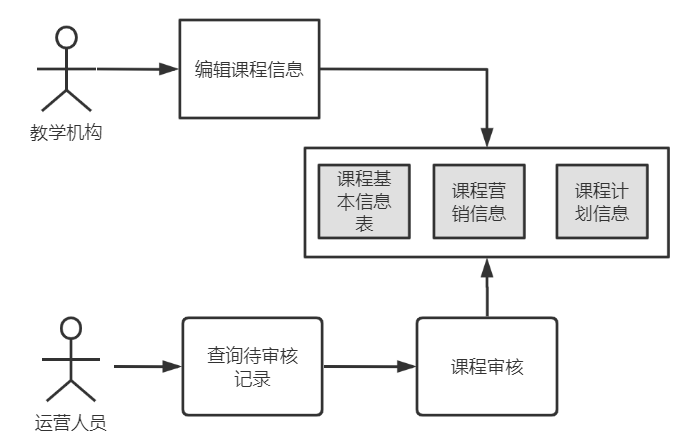

讲义增加 `course_publish_pre`，在提交审核时聚合一份快照。审核员读取这份固定内容，机构继续编辑原来的草稿。

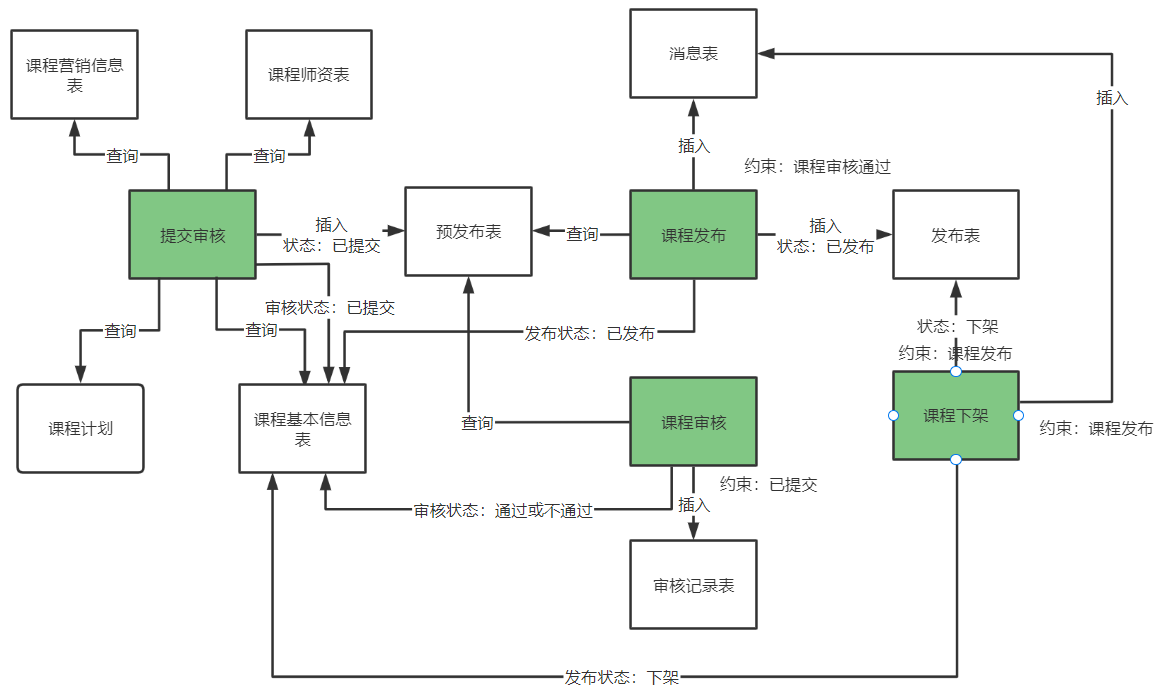

| 数据 | 表或来源 | 谁使用、何时变化 |
| --- | --- | --- |
| 编辑数据 | `course_base`、`course_market`、课程计划和媒资关系 | 机构修改；动态预览读取 |
| 待审核快照 | `course_publish_pre` | 提交时保存；审核期间保持内容固定 |
| 正式发布快照 | `course_publish` | 审核通过后发布；线上派生数据以它为来源 |
| 审核记录 | 讲义设计的审核记录表 | 记录审核人员、时间、结果和意见 |

例子：10:00 提交 A 版本，10:30 将草稿改成 B，11:00 审核 A 通过。此时发布的应是 **A**。B 要重新提交并通过审核后，才成为新的正式发布内容。

提交待审后不能再次提交覆盖同一条预发布记录，否则会改变正在审核的对象；审核结束后再提交新快照。原课程用按课程 ID 覆盖的预发布记录描述这个流程，完整版本历史、审核记录和审计需要进一步设计。

**补充：**快照保存课程数据和媒资标识，并不必然冻结视频文件本身。如果同一媒资 ID 指向的文件可以被替换，还应保证对象不可变或记录媒资版本，否则已审核课程的视频也可能悄悄变化。


## 12. 提交审核接口和约束

接口路径与服务签名：

```java
@ResponseBody
@PostMapping("/courseaudit/commit/{courseId}")
public void commitAudit(@PathVariable("courseId") Long courseId) {
    Long companyId = 1232141425L; // 课堂临时机构 ID。
    coursePublishService.commitAudit(companyId, courseId);
}
```

```http
POST http://localhost:63040/content/courseaudit/commit/74
```

提交之前至少要检查：

1. 课程存在，且当前机构拥有该课程。
2. 当前审核状态不是 `202003`，防止重复覆盖待审快照。
3. 课程已上传图片。
4. 课程已有教学计划。

day08 源码检查了课程是否存在、是否待审、图片与计划是否为空，并在方法上加了 `@Transactional`。但“本机构只能提交本机构的课程”仍为待实现注释，传入 `companyId` 后直接写入预发布表，**传参不等于已经完成权限校验**。

**补充：**正式接口从登录上下文取得机构身份，服务层再核对课程归属，不能由前端任选机构 ID。非空的计划树也不证明它有可学习的小节；按业务规则还应检查小节、视频绑定、媒资可用性、收费价格和必填字段。

请求中没有 JSON body，课程 ID 在路径里；当前代码返回 `void`，成功后前端应刷新课程状态。它只提交审核，不负责立即批准，也不负责立即生成正式 HTML。


## 13. 保存预发布快照的核心实现

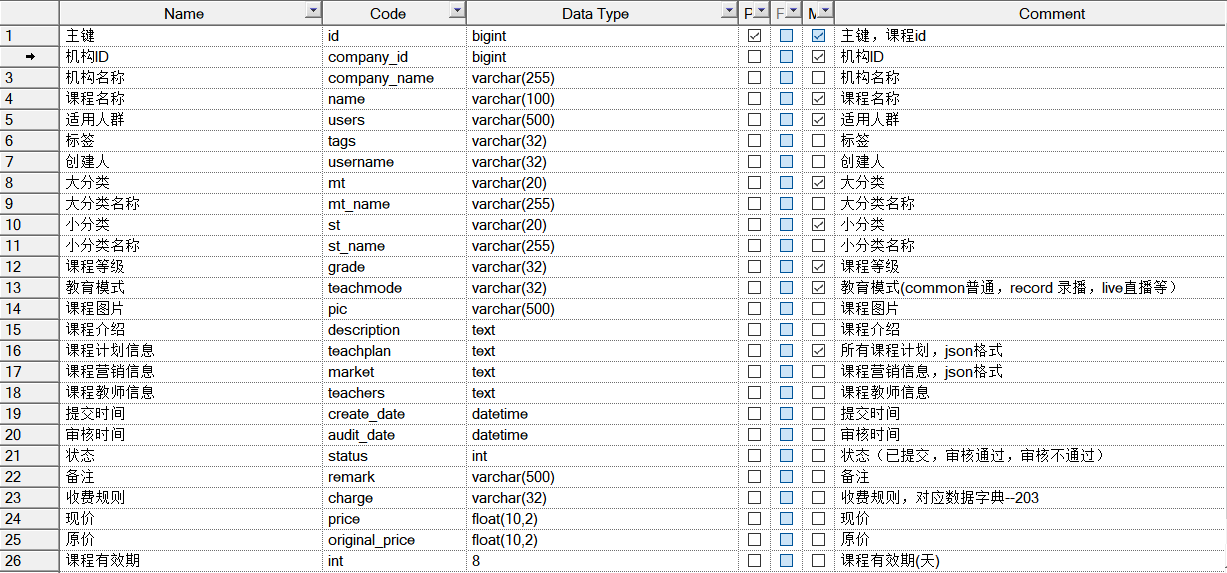

预发布表保存基础字段，以及 `market`、`teachplan` 等 JSON 快照。它的 `id` 沿用课程 ID，**不是每次提交新生成一个课程 ID**。营销信息和计划树保存成 JSON 后，后续编辑原表不会自动更新这份字符串。

下面按源码流程整理，并补齐机构校验、空值判断和写入结果检查；依赖均为项目中已有的成员，`Objects` 为 `java.util.Objects`。此片段用于理解本地事务，未包含第 14 节的并发控制：

```java
@Transactional(rollbackFor = Exception.class)
public void commitAudit(Long companyId, Long courseId) {
    CourseBaseInfoDto info =
            courseBaseInfoService.getCourseBaseInfo(courseId);
    if (info == null) {
        XueChengPlusException.cast("课程不存在");
    }
    if (companyId == null
            || !Objects.equals(companyId, info.getCompanyId())) {
        XueChengPlusException.cast("不允许提交其他机构的课程");
    }
    if ("202003".equals(info.getAuditStatus())) {
        XueChengPlusException.cast("课程已提交，请等待审核");
    }
    if (StringUtils.isEmpty(info.getPic())) {
        XueChengPlusException.cast("请上传课程图片");
    }
    List<TeachplanDto> tree =
            teachplanService.findTeachplanTree(courseId);
    if (tree == null || tree.isEmpty()) {
        XueChengPlusException.cast("请编写课程计划");
    }

    CoursePublishPre snapshot = new CoursePublishPre();
    BeanUtils.copyProperties(info, snapshot);
    snapshot.setCompanyId(companyId);
    snapshot.setMarket(JSON.toJSONString(
            courseMarketMapper.selectById(courseId)));
    snapshot.setTeachplan(JSON.toJSONString(tree));
    snapshot.setStatus("202003");
    snapshot.setCreateDate(LocalDateTime.now());

    CoursePublishPre existing =
            coursePublishPreMapper.selectById(courseId);
    int saved = existing == null
            ? coursePublishPreMapper.insert(snapshot)
            : coursePublishPreMapper.updateById(snapshot);
    requireOne(saved);

    CourseBase base = courseBaseMapper.selectById(courseId);
    if (base == null) {
        XueChengPlusException.cast("课程不存在");
    }
    base.setAuditStatus("202003");
    requireOne(courseBaseMapper.updateById(base));
}

private void requireOne(int affected) {
    if (affected != 1) {
        XueChengPlusException.cast("数据写入失败");
    }
}
```

`BeanUtils.copyProperties` 按同名兼容属性复制，不会自动查询计划、序列化营销信息，也不会转换审核/发布状态。需要显式设置的字段要自己赋值。

源码允许营销记录缺失后被序列化为 `"null"`；这只是 JSON 转换的结果，不表示信息完整。是否允许提交，应按免费/收费课程等业务规则校验。PO 有 `teachers` 属性，但本日没有把完整师资数据写入快照。

资料中的 `createDate` 在预发布表表示提交时间；正式发布表注释表示发布时间。两个字段名字相同，直接复制时容易把提交时间带到发布时间，发布时应明确时间语义。


## 14. 审核的事务、并发与模拟测试

保存快照与更新 `course_base.audit_status` 必须共同成功，否则会出现“基础表待审却没有快照”或“快照待审但基础表仍未提交”。day08 源码已有本地事务；讲义展示的提交审核方法没有写出该注解，学习时以最终事务边界为准。

事务仍有几个前提：方法经 Spring 代理调用，写入使用同一事务管理器与数据源，失败抛出会触发回滚的异常。Mapper 返回 0 不会自动让事务回滚；若业务要求必需更新一条，应主动检查结果。默认 `@Transactional` 通常对运行时异常回滚，需覆盖受检异常时可配置 `rollbackFor`。

**并发补充：**两个请求都先读到“未提交”，随后都写入快照，不能因为加了事务就断言不会覆盖。常见办法包括：

- 对同一课程使用数据库行锁，且所有提交路径遵守同一加锁规则。
- 用状态和版本号做条件更新，只有预期状态/版本匹配才能提交，失败则整体回滚。
- 审核动作也按预发布快照版本校验，避免批准已被替换的内容。

快照还跨多个编辑表聚合。若允许草稿并发修改，应明确事务隔离和草稿版本，让提交的数据来自同一个逻辑版本；仅锁基础表而其他编辑接口完全不遵守锁，并不能自动冻结全部关联数据。

讲义在课堂只实现机构提交审核，运营审批用**手工改状态模拟**：把预发布表 `status` 和基础表 `audit_status` 改为 `202004`。这是实验准备步骤，不能替代完整审批接口，也不能只改其中一张表就认为生命周期一致。

建议在自己的测试环境验证：

1. 无图、无计划、重复提交、跨机构提交均得到明确失败。
2. 正常提交后，快照 JSON 包含当时的营销与计划，基础表变待审。
3. 待审期间修改草稿，预发布内容不跟着变化。
4. 审核结束再提交，快照更新成新内容，重新变待审。
5. 模拟写入失败，快照与状态都回滚；并发提交只有符合预期的版本生效。

这些是验证目标。本次写笔记未连接数据库修改审核状态。


## 15. 课程发布要同步四份数据

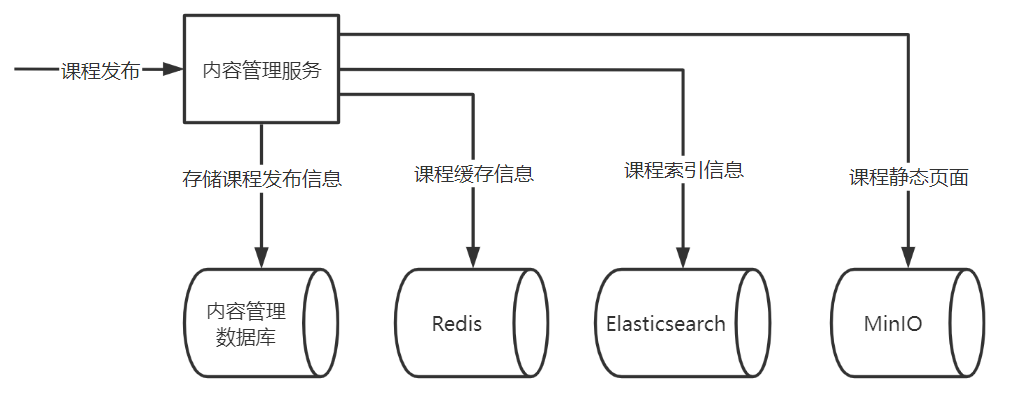

| 位置 | 保存内容 | 使用场景 |
| --- | --- | --- |
| MySQL `course_publish` | 完整正式发布快照 | 发布事实与派生数据的来源 |
| Redis | 课程查询所需缓存 | 减少重复数据库查询 |
| Elasticsearch | 名称、介绍等可检索字段 | 搜索课程 |
| MinIO | 生成的课程 HTML | 快速访问课程详情页 |

这些数据不是四张完全相同的表。搜索文档、缓存对象、HTML 各自按用途从正式快照派生。后续页面静态化应读取发布快照，不能再次读取最新草稿。

**day08 源码与讲义差异：**源码的 `publish()` 把预发布 PO 直接复制到 `CoursePublish`，没有显式把 `status` 改成 `203002`，也没有更新基础表的发布状态；因而可能把预发布表的 `202004` 带进正式发布表。讲义的完整 `saveCoursePublish()` 则设置 `203002` 并更新基础表。第 19 节示例按讲义目标补齐这些步骤。

源码还没有实现发布时的机构归属检查，也没有把提交时间明确改成发布时间。查看发布记录时不能只看“表里有一行”，还要看状态、机构、快照内容和时间是否正确。


## 16. 本地事务、CAP 与 BASE

Spring 的数据库事务依赖数据库连接。数据库可以回滚本地表更新，但不能自动撤销已经成功的 Redis 写入、ES 索引写入或 MinIO 上传。

```text
开始数据库事务
  写 course_publish
  远程写入 MinIO：实际成功，但响应在网络中丢失
  调用方超时并回滚数据库
结果：数据库没有发布成功，MinIO 却已经有文件
```

远程超时表示“调用方未及时获知结果”，结果可能成功、失败或仍在执行；直接当作失败并重发，可能产生重复副作用。

CAP 的三个概念应准确理解：

| 概念 | 含义 | 常见误解 |
| --- | --- | --- |
| C，一致性 | 线性一致性的读写语义，操作看起来按单一全局顺序生效 | 与 ACID 的数据库一致性完全相同 |
| A，可用性 | 非故障节点收到请求，能在有限时间内完成符合语义的响应 | 任何时候显示页面或返回一个错误也算满足 |
| P，分区容忍 | 在节点间通信可能丢失/中断的模型下讨论系统行为 | 所有功能在分区时都必须可用 |

**讲义表述校正：**CAP 的关键冲突发生在网络分区时，无法同时保证严格的 C 和 A；不是正常网络下永远“三选二”，也不是选某个事务框架就能给整个产品统一贴 CP/AP 标签。分布式数据库的 ACID 与 CAP 描述的性质也不能混为一谈。

BASE 用于理解允许延迟的业务方案：基本可用、软状态、最终一致。课程发布可以先记录本地发布结果，再显示“同步中”，等后台派生数据就绪。

最终一致成立需要前提：任务可靠保存、失败可重试、重复执行安全、版本不倒退、长期失败可发现和修复。网络永久故障或任务一直失败时不会自动收敛。“等一会儿自然一致”不是技术方案。


## 17. 分布式事务方案怎样选择

讲义介绍 AT、TCC、消息通知和任务扫描。本项目课程发布选择 **本地消息表 + 定时任务**，没有在本日接入 Seata。

| 方案 | 核心方式 | 成本与适用条件 |
| --- | --- | --- |
| 2PC / XA | 多资源由协调者准备、提交 | 资源要支持协议；锁与故障恢复成本较高 |
| Seata AT | 本地提交、记录回滚信息、协调全局结果 | 有数据源及 SQL 适配限制；不能直接覆盖任意远程副作用 |
| TCC | 业务提供 Try / Confirm / Cancel | 对预留资源与补偿有侵入；要处理空回滚、幂等和悬挂 |
| 可靠消息 / 事务消息 | 保存业务事件，驱动下游异步处理 | 要解决事件可靠产生、重复投递、顺序与失败恢复 |
| 本地消息表 | 业务数据和待办事件在同一事务落库，再扫描执行 | 依赖扫描、幂等、归档、重试与监控，增加同步延迟 |

这些是协议和实现路线，不等于对任何系统都能保证“所有节点立即看到相同数据”。特别是 AT 的本地事务已先提交，其隔离语义要结合全局锁和读取方式理解；TCC 的最终效果取决于业务 Confirm/Cancel 是否正确实现。

课程 HTML、索引和缓存都可以由正式数据库重新构建，业务可接受有限同步延迟，加上已经接入 XXL-JOB，因此本地消息表较符合课堂项目的积累。

设计时先确定：什么必须同步决定、什么可以稍后完成、允许多长延迟、失败如何展示和修复。不能把“余额变更”和“发布后生成搜索索引”一律套成同一个一致性要求。


## 18. 本地消息表如何减少任务丢失

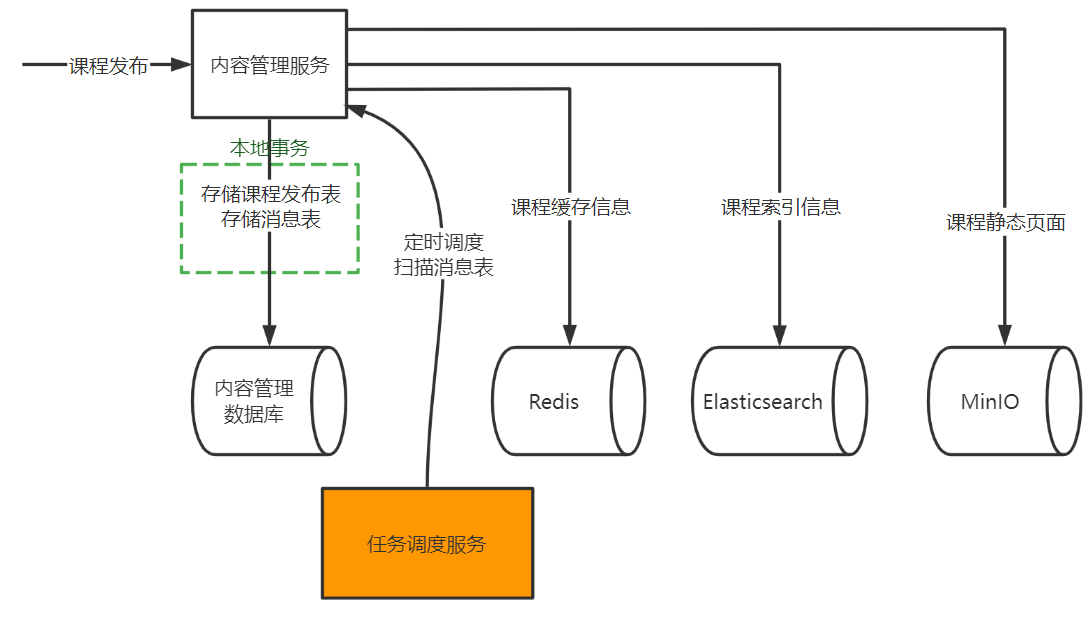

本地消息表也常被称为 Outbox。课程发布在同一数据库事务里写正式快照和 `mq_message`：

```text
本地事务：
  校验预发布快照已审核通过
  保存 course_publish / 更新基础表发布状态
  插入 message_type=course_publish 的消息
  删除本次已发布的预发布记录
提交事务

后台任务：
  扫描待处理消息 → 按发布数据执行同步
  成功 → 消息归档；失败 → 保留活动消息，后续扫描再执行
```

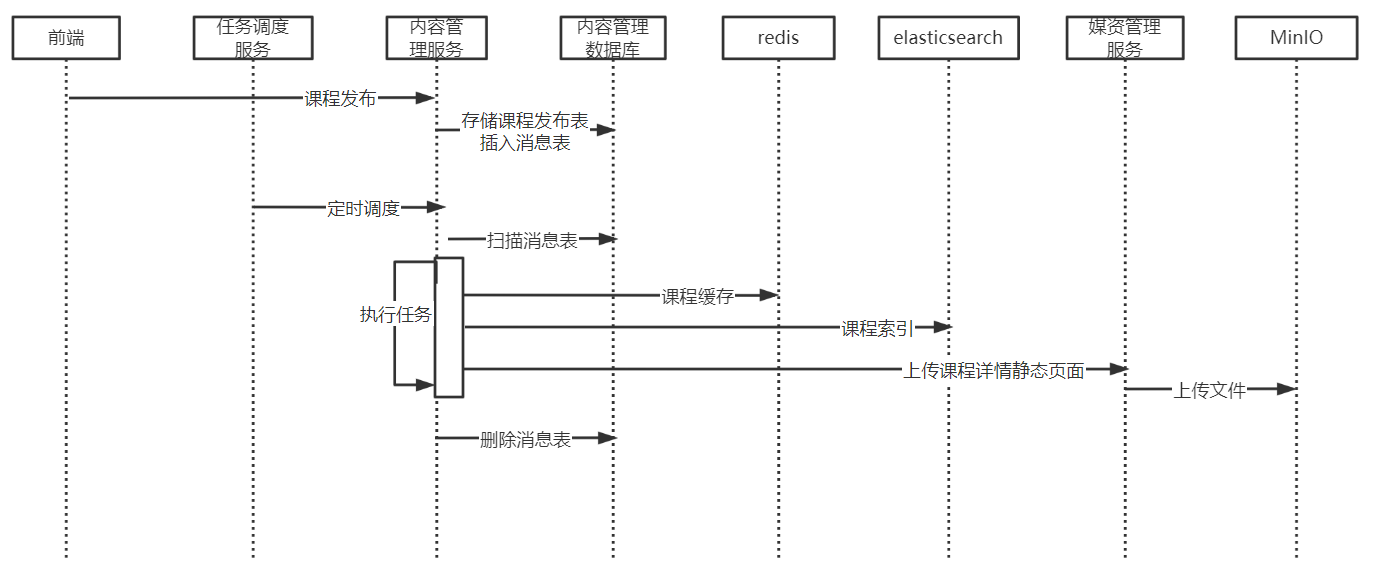

它解决的关键问题是：进程如果在提交事务后立即退出，消息还在数据库，后续能继续扫描；消息写入失败则发布数据也应回滚。不能“先提交发布表，再单独创建消息”，两步之间崩溃会丢失待办任务。

要同时满足 **同一数据库、同一数据源/事务管理器、同一事务参与关系**。SDK 只是被调用的组件，不会凭名字自动加入事务；如果把消息写到另一个数据库或另开独立事务，这个原子性依据就变了。

发布接口返回成功说明本地发布记录与待办消息已提交。此时索引、缓存和 HTML 可能尚未就绪。产品可在必要时区分“已提交发布”和“对外就绪”，但课堂没有完整实现这套同步进度 UI。

原模型倾向于反复投递直到成功，因此目标通常是 **至少一次执行机会 + 幂等效果**。它不是只执行一次的保证。


## 19. 发布接口与事务实现

发布接口为 `POST /coursepublish/{courseId}`，控制器上的 `@ResponseBody` 及临时机构 ID 与提交审核相同。服务层必须以已审核的预发布快照为依据。

```http
POST http://localhost:63040/content/coursepublish/74
```

下面按讲义最终目标结合源码整理，补齐机构校验、发布状态、发布时间和影响行数检查。仍需另外加入并发/版本控制；复用第 13 节的 `requireOne()`：

```java
@Transactional(rollbackFor = Exception.class)
public void publish(Long companyId, Long courseId) {
    CoursePublishPre pre =
            coursePublishPreMapper.selectById(courseId);
    if (pre == null) {
        XueChengPlusException.cast("请先提交审核，通过后才可发布");
    }
    if (companyId == null
            || !Objects.equals(companyId, pre.getCompanyId())) {
        XueChengPlusException.cast("不能发布其他机构的课程");
    }
    if (!"202004".equals(pre.getStatus())) {
        XueChengPlusException.cast("课程没有审核通过");
    }

    CourseBase base = courseBaseMapper.selectById(courseId);
    if (base == null
            || !Objects.equals(companyId, base.getCompanyId())) {
        XueChengPlusException.cast("课程不存在或机构不匹配");
    }

    CoursePublish published = new CoursePublish();
    BeanUtils.copyProperties(pre, published);
    published.setStatus("203002");
    published.setCreateDate(LocalDateTime.now());
    CoursePublish existing = coursePublishMapper.selectById(courseId);
    int saved = existing == null
            ? coursePublishMapper.insert(published)
            : coursePublishMapper.updateById(published);
    requireOne(saved);

    base.setStatus("203002");
    requireOne(courseBaseMapper.updateById(base));

    MqMessage message = mqMessageService.addMessage(
            "course_publish", String.valueOf(courseId), null, null);
    if (message == null) {
        XueChengPlusException.cast("发布消息保存失败");
    }
    requireOne(coursePublishPreMapper.deleteById(courseId));
}
```

删除预发布记录在事务内完成，正式快照已保存在 `course_publish`；消息不能只指望稍后再去读取已删除的预发布数据。源码的 `saveCoursePublishMessage()` 也在消息返回 `null` 时抛业务异常，让外层事务回滚。

**并发补充：**重复点击、响应丢失后的重试、同课程新审核与旧发布竞争，都需要锁/版本或请求幂等键。当前先查再写不是完整并发方案；按 ID 删除预发布记录，也要防止误删并发生成的新版本。

**时间补充：**上面只明确设置发布时间；是否同步设置 `onlineDate`、怎样保留每次发布的历史，要依业务定义实现。不能认为 `BeanUtils` 自动处理这些生命周期字段。


## 20. 消息表字段、默认值与映射

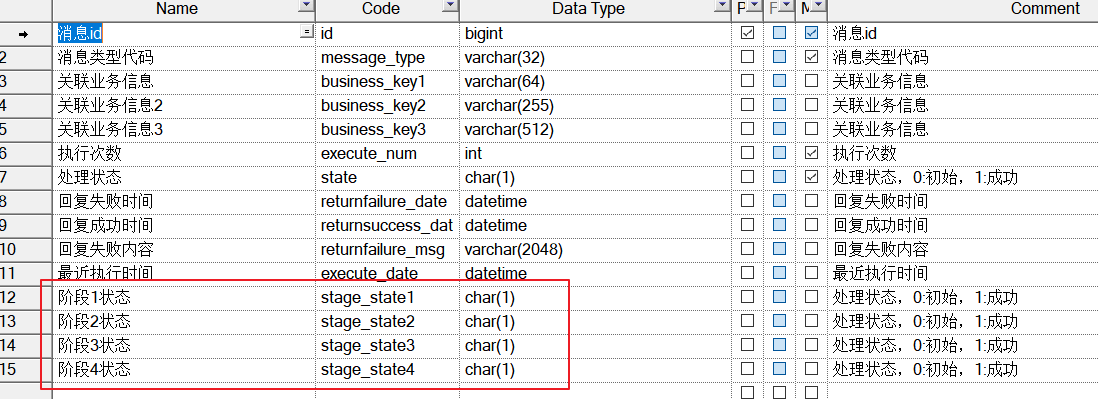

| PO 字段 | 用途 | 本课程的典型值 |
| --- | --- | --- |
| `id` | 自增 Long 消息 ID；用于分片、阶段更新和归档 | 一次任务的唯一标识 |
| `messageType` | 业务任务类型 | `course_publish` |
| `businessKey1` | 第一关联业务标识 | 课程 ID 的字符串 |
| `businessKey2/3` | 其他关联业务信息 | 原发布消息传 `null` |
| `state` | 消息处理状态 | `0` 初始、`1` 成功 |
| `stageState1..4` | 阶段处理状态 | `0` 初始、`1` 成功 |
| `executeNum`、`executeDate` | 执行次数和最近执行时间 | PO 提供字段，当前处理器未完整维护 |
| 成功/失败时间与错误信息 | 追踪任务结果 | 字段存在不代表自动填充 |

`MqMessage` 以 `@TableName("mq_message")` 映射活动表，`@TableId(type = IdType.AUTO)` 声明自增主键；`MqMessageHistory` 用于历史表。消息 ID 和课程 ID 不能混用，阶段更新使用前者。

**默认值核对：**源码 `addMessage()` 只设置类型与三个业务键，没有设置 `state`、阶段状态和执行次数，PO 也没有初始化这些字段。若实际表没有默认 `0`，`state='0'` 的扫描查不到记录，阶段状态解析也可能报错。可在插入前显式初始化，或使用并核验数据库默认值：

```java
// 补充：加入 SDK 的 addMessage()，在 insert 之前执行。
mqMessage.setState("0");
mqMessage.setStageState1("0");
mqMessage.setStageState2("0");
mqMessage.setStageState3("0");
mqMessage.setStageState4("0");
mqMessage.setExecuteNum(0);
```

**映射差异：**源码 PO 与 XML ResultMap 用 `execute_num/execute_date`，但 `MqMessageMapper.xml` 的 `Base_Column_List` 仍写 `inform_num/inform_date`；讲义表结构截图也使用后者。当前自定义扫描是 `SELECT t.*`，没有直接引用这个列清单，但字段自动映射、插入和后续自定义 SQL 仍应与实际表一致。

本次未取得可逐列验证的内容库建表 SQL，所以不在这里虚构一份“原始 DDL”。实践时对照实际消息表/历史表统一字段名、类型和默认值，确认扫描能取出新消息，再进行后台任务联调。


## 21. 消息 SDK 是嵌入式组件

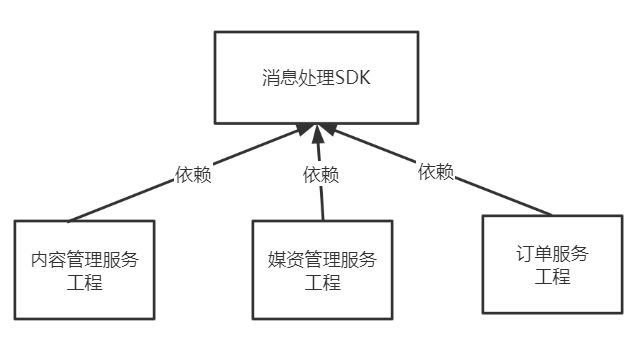

SDK 提供消息表访问、分片扫描、阶段状态与完成归档；课程、媒资或订单服务各自实现业务任务。它通过 Java 依赖嵌入服务进程，**不是独立部署的消息中心，也不是 RabbitMQ 的队列**。

内容 Service 工程的实际依赖为：

```xml
<dependencies>
    <dependency>
        <groupId>com.xuecheng</groupId>
        <artifactId>xuecheng-plus-message-sdk</artifactId>
        <version>0.0.1-SNAPSHOT</version>
    </dependency>
    <dependency>
        <groupId>com.xuxueli</groupId>
        <artifactId>xxl-job-core</artifactId>
    </dependency>
</dependencies>
```

XXL-JOB 的版本由父 POM 管理，本次读取值为 `2.3.1`。SDK 的 Spring Service、Mapper 和配置类也要被扫描到，仅加入 Maven 依赖不代表它们必然成为 Bean。

day08 的 `ContentApplication` 在 `com.xuecheng` 包，默认组件扫描能够覆盖 `com.xuecheng.content` 和 `com.xuecheng.messagesdk`。SDK 的配置类使用 `@MapperScan("com.xuecheng.messagesdk.mapper")`，配置 Bean 名为 `messagesdk_mpconfig`。

若把启动类移动到更窄的包中，要重新检查扫描范围。出现找不到 `MqMessageService` 或 Mapper Bean 时，应检查依赖、组件扫描、Mapper 扫描及数据源，而不是只创建一个同名空类绕过错误。


## 22. SDK 接口分别负责什么

| 方法 | 职责 | 使用注意 |
| --- | --- | --- |
| `addMessage(type,key1,key2,key3)` | 新增待办消息，成功返回实体 | 发布事务内调用；检查结果与初始状态 |
| `getMessageList(index,total,type,count)` | 获取当前分片待处理消息 | 参数范围和数量要受控 |
| `getStageOne/Two/Three/Four(id)` | 读取相应阶段状态 | 当前实现没有完整空值/已归档保护 |
| `completedStageOne/Two/Three/Four(id)` | 设置阶段完成 | 外部操作确实完成后再写；检查影响行数 |
| `completed(id)` | 标成功、插历史、删活动消息 | 业务需要先确认必需阶段均已成功 |

`MessageProcessAbstract` 提供抽象业务入口：

```java
public abstract boolean execute(MqMessage mqMessage);
```

返回 `true` 表示调用方认定整个业务任务完成，框架随后调用 `completed()`；返回 `false` 或抛异常时，框架不会走成功归档路径。

**源码校正点：**`getStageOne()` 实际直接执行：

```java
return Integer.parseInt(
        mqMessageMapper.selectById(id).getStageState1());
```

消息不存在、已被另一个线程归档、阶段字段为 `null` 或非数字时都会出错。讲义提到“消息不存在就不用执行”，但这个 getter 本身没有实现优雅跳过，需要业务入口及状态读取补齐。

SDK 本身不认识“静态 HTML 是否上传成功”，也不验证课程已通过审核。它只有通用状态接口，业务方负责把实际完成条件与状态标记联系起来。


## 23. 分片扫描消息的 SQL

SDK 的自定义扫描 SQL 为：

```sql
SELECT t.*
FROM mq_message t
WHERE t.id % #{shardTotal} = #{shardindex}
  AND t.state = '0'
  AND t.message_type = #{messageType}
LIMIT #{count}
```

这些是 MyBatis 占位符，不是可原样粘贴进数据库客户端执行的 SQL。Service 参数顺序是 `shardIndex, shardTotal`，但内部 Mapper 方法先传 `shardTotal` 再传 `shardIndex`，阅读时要核对顺序和名称。

例如两个分片：序号 0 处理偶数消息 ID，序号 1 处理奇数 ID。分片按**消息 ID**计算，不按课程 ID，也不是“一门课程固定只能由某个执行器处理”。

与第 07 篇的视频任务扫描不同，消息 SDK 没有 `fail_count < 3` 这个条件。原 SQL 也没有执行次数上限、下次重试时间或 `ORDER BY`，不能把前篇视频任务的失败控制自动套到这里。

**补充：**应验证 `shardTotal > 0`、`0 <= shardIndex < shardTotal`、`count` 合理，并结合业务选择排序、索引和公平性策略。增加 `ORDER BY id` 能明确顺序，但永久失败的前排任务若一直占满 LIMIT，还需要退避/隔离避免后续任务长期得不到机会。

分片解决“这轮怎样分工”，不自动完成原子认领。拓扑变化、并发调用、超时未结束或执行器重复触发时仍可能处理同一消息。


## 24. 多线程处理器的实际行为

`MessageProcessAbstract.process()` 的源码流程如下：

```text
查询当前分片消息列表
  → 空列表直接返回
  → 创建线程数等于消息数量的固定线程池
  → 每条消息提交一个 worker
  → worker 调用 execute(message)
      true：调用 completed(message.id)
      false：保留消息
      异常：记录日志，保留消息
      finally：CountDownLatch 减 1
  → 调度线程 await(timeout, SECONDS)
  → 方法返回
```

本次两个代码包的 SDK 都把 `countDown()` 放在 `finally`，讲义展示的旧片段在 `try/catch` 之后。笔记以实际 ZIP 源码为准。`@Data` 为抽象类生成了 `getMqMessageService()`，子类借它访问阶段状态服务。

源码需要理解的限制：

1. 每轮重新创建线程池，数量等于本轮消息数；`count=30` 时最多创建 30 个 worker，而不是全系统固定只有 30 个线程。
2. 没有调用 `shutdown()`，多轮扫描会留下线程池资源。
3. 没有检查 `await()` 的布尔返回值，无法区分“全部已结束”和“等待时间已到”。
4. 等待超时后 worker 仍可运行；参数注释“到点强制结束”与实现不一致。
5. 捕获 `InterruptedException` 后只打印，没有恢复中断状态。
6. worker 异常仅写日志，没有统一传播为 XXL-JOB 业务失败结果。

**超时校正：**`CountDownLatch.await(60, SECONDS)` 只让当前线程最多等待 60 秒，不会杀死线程、撤回远程请求或自动回滚 MinIO/ES 写入。即使另加 `Future.cancel(true)`，中断也需要业务代码和客户端配合，不能保证远端副作用停止。

**补充方向：**复用受控线程池与有界队列，给远程请求单独配置超时，检查等待结果，记录各 worker 结果，正确关闭/管理资源并恢复中断。必要时由主调度线程汇总后显式报告失败，不能依赖 worker 的日志让调度中心自动识别业务失败。


## 25. day08 的课程发布任务仍是演示骨架

项目中的类为 `CoursePublishTask extends MessageProcessAbstract`。它已使用 `Long.parseLong()` 解析业务键，这比讲义旧片段的 `Integer.parseInt()` 更符合 Long 课程 ID：

```java
@Override
public boolean execute(MqMessage mqMessage) {
    Long courseId = Long.parseLong(mqMessage.getBusinessKey1());
    generateCourseHtml(mqMessage, courseId);
    saveCourseIndex(mqMessage, courseId);
    // 源码此处只有“向 redis 写缓存”的注释。
    return true;
}
```

阅读这些方法名不能断言它们已实现业务。day08 实际情况是：

| 阶段 | 讲义演示 | 本次项目源码 |
| --- | --- | --- |
| HTML | 睡眠模拟耗时，完成第一阶段标记 | 检查第一阶段后主动制造除零异常；未生成/上传 HTML |
| 搜索索引 | 睡眠模拟 | 只有查询/调用搜索的注释，然后设置第二阶段完成 |
| Redis 缓存 | 睡眠模拟 | 执行入口仅有注释，没有实际缓存调用 |

第一阶段的失败注入原样是：

```java
int i = 1 / 0; // 课堂用来制造任务执行异常。
```

因此按原包执行，第一阶段尚未完成的消息会失败并保留。只删掉这句，方法也没有因此生成 HTML；若直接写完成标记，就会制造“状态已成功、外部数据未生成”的错误。第二阶段原占位实现同样不能当作搜索索引已写入。

后续完整实现应遵守这样的合同：

```text
execute(message):
  校验消息、课程 ID、发布版本
  HTML 阶段：读取已发布快照 → 渲染/上传 → 确认结果 → 写阶段标记
  索引阶段：写入目标版本索引 → 确认结果 → 写阶段标记
  缓存阶段：写入目标版本缓存 → 确认结果 → 写阶段标记
  必需阶段全部完成：返回 true
  任一阶段失败：抛异常或返回 false，保持可恢复状态
```

这里是后续实现要求，本日没有用占位成功代码冒充真正的 MinIO、ES 和 Redis 同步。


## 26. 阶段状态为什么仍需要幂等

阶段状态使失败任务可以跳过已经确认完成的步骤。例如 HTML 已完成、索引失败，重试时无需再次生成相同 HTML。

```text
首次执行：HTML 成功并记 stage1=1 → 索引失败 → 整体保留
下次执行：跳过 HTML → 重试索引 → 缓存成功 → 归档
```

阶段标记减少重复，却不能单独保证 exactly-once。外部系统与本地消息表之间存在无法靠普通数据库事务消除的窗口：

| 失败位置 | 后果 | 应对 |
| --- | --- | --- |
| 外部写入成功，阶段标记之前退出 | 重启后阶段仍为 0，再次执行 | 目标写入必须幂等 |
| 外部写入超时，实际已成功 | 调用方不知道结果，可能重发 | 同一业务/版本幂等键，必要时查询结果 |
| 先写阶段完成，再调用外部系统 | 外部失败后仍会被跳过 | 外部确认成功后再写完成状态 |
| 两个 worker 都读到阶段 0 | 同阶段并发执行 | 认领/锁或目标端幂等与版本控制 |
| 阶段更新影响行数为 0，却继续归档 | 状态可能丢失或已被其他执行者改变 | 明确已完成/已归档/冲突语义并检查结果 |

目标操作可设计为：相同课程及版本写同一对象/文档/缓存键，多次执行效果相同。但“相同键覆盖”还需要内容属于同一版本；若旧版本覆盖新版本，会破坏正确结果。

幂等是重复执行的**业务效果不变**，不是“永远不调用第二次”。发短信、扣费等非覆盖式副作用需要另外的业务去重机制，不能套用信息同步任务的简化假设。


## 27. 归档、失败重试与版本防倒退

SDK 的 `completed(id)` 有本地事务，执行“按 ID 更新 state=1 → 查询消息 → 复制进历史表 → 删除活动消息”。这能把正常成功任务从待办集合移走，保留历史。

但当前代码没有自动检查全部阶段，也没有验证历史插入/活动删除的影响行数，更新条件也只按 ID。它依赖业务 `execute()` 正确返回，仍要处理重复完成和并发归档，不能只凭 `@Transactional` 认定逻辑完整。

失败时，活动消息通常仍是 `state=0`，下一轮扫描可再次取到。**当前 SDK 没有完整维护执行次数、错误信息、最大重试次数和指数退避**；PO 里有这些字段并不表示功能已实现。永久错误可能被不断扫描，调度中心也可能只看到调度方法正常返回。

建议补齐的恢复能力：

- 每次尝试记录次数、最近时间和错误原因；短暂错误按退避重试。
- 超过阈值或确定为不可恢复错误时，隔离任务并提供人工修复入口。
- 监控最老未完成消息、积压量、各阶段延迟及失败率。
- 归档前校验必需阶段，归档写入与删除结果异常时回滚。
- 定期核对正式发布版本与各目标版本，发现丢失或不一致后重建。

**版本补充：**原消息只保存 `businessKey1=courseId`，`businessKey2/3=null`，没有固定发布版本。如果课程短时间内发布 A、B，两条消息可以同时执行；A 的慢任务最后写入，可能覆盖 B。

```text
A 任务读到 A → 开始慢速渲染
B 发布并同步 B → 目标已是 B
A 任务稍后写入 A → 目标倒退为 A
```

改进时把发布版本/快照标识放入事件，并能读取对应的不可变快照；目标端用原子版本比较拒绝旧版本，或保证同课程有序处理及可靠的过期任务处置。**只给消息加一个版本字段，目标仍无条件覆盖，并不能解决倒退。**

HTML 可以采用版本对象路径，再切换当前版本指针；索引和缓存可使用支持原子比较的版本策略。具体实现留到对应系统，不把这些改进描述成原 SDK 已提供。


## 28. XXL-JOB 接入和任务配置

讲义把配置加在 Nacos 的 `content-service-dev.yaml`。地址和端口是课程环境示例，实际部署要与当前网络、执行器和调度中心配置一致：

```yaml
xxl:
  job:
    admin:
      addresses: http://192.168.101.65:8088/xxl-job-admin
    executor:
      appname: coursepublish-job
      address: ""
      ip: ""
      port: 8999
      logpath: /data/applogs/xxl-job/jobhandler
      logretentiondays: 30
    accessToken: default_token
```

`8999` 是执行器通信端口，`63040` 是内容 API 的 HTTP 端口，`8088` 是示例调度中心端口，三者用途不同。Windows 本机部署时还应把日志目录改成实际可写路径；示例 token 也应与调度中心保持一致并按环境管理。

源码已有 `XxlJobConfig`，通过 `@Value` 读取这些参数并创建 `XxlJobSpringExecutor`。配置类进入组件扫描、Nacos 配置成功加载后，执行器才有机会注册到调度中心。

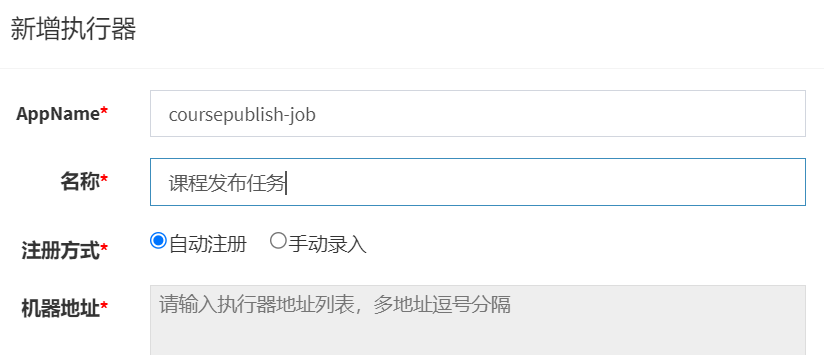

入口使用名称完全一致、大小写准确的 Handler：

```java
@XxlJob("CoursePublishJobHandler")
public void coursePublishJobHandler() throws Exception {
    int shardIndex = XxlJobHelper.getShardIndex();
    int shardTotal = XxlJobHelper.getShardTotal();
    process(shardIndex, shardTotal, "course_publish", 30, 60);
}
```

五个参数依次是分片序号、分片总数、消息类型、每轮最多消息数、等待秒数。`30` 不是重试次数，`60` 不是数据库事务时长，也不是所有业务线程的强制终止时间。

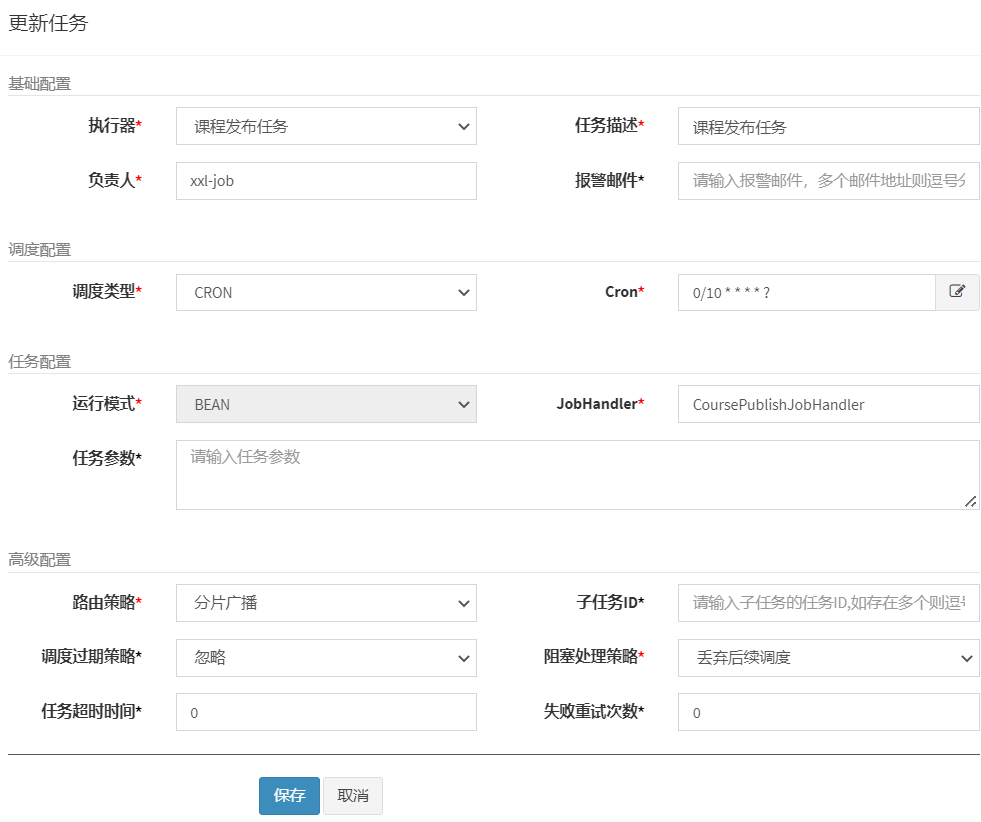

讲义截图对应设置：

| 配置项 | 示例值 | 作用 |
| --- | --- | --- |
| AppName | `coursepublish-job` | 与执行器配置一致 |
| 调度类型 | CRON，`0/10 * * * * ?` | 示例每 10 秒触发 |
| 运行模式 | BEAN | 调用注解标识的任务方法 |
| JobHandler | `CoursePublishJobHandler` | 与 `@XxlJob` 完全匹配 |
| 路由策略 | 分片广播 | 传入分片序号和总数 |
| 阻塞处理策略 | 丢弃后续调度 | 同一 handler 正在执行时丢弃后续触发 |
| 调度过期策略 | 忽略 | 截图中的实验设置 |
| 任务超时 / 失败重试次数 | `0` / `0` | 这两个调度设置不等于业务消息不重试 |

XXL 的阻塞策略主要约束它正在管理的 handler。原 `process()` 在等待超时后提前返回，而 worker 仍在执行，下一轮仍可能与旧 worker 重叠；所以“分片广播 + 丢弃后续”不能证明任务不会重复。


## 29. 从接口到消息的联调与故障验证

下面是实际学习时的执行顺序和预期结果，本次仅静态核对资料与笔记，未运行这些实验。

1. 确认内容服务、数据库、Nacos、网关、门户与必要依赖处于同一环境，模板能正常加载。
2. 通过门户预览课程，确认名称、分类、价格、图片、目录、小节和视频链接均来自正确数据。
3. 调用提交审核，检查基础表待审状态，以及预发布快照的机构、内容 JSON 和时间。
4. 修改草稿，再读取预发布快照，验证审核内容仍固定；待审再次提交应失败。
5. 在测试环境按讲义模拟审核通过，核对基础表和预发布表都为 `202004`。
6. 发布后检查正式发布表、基础表发布状态、预发布删除以及消息记录；消息类型为 `course_publish`，业务键为课程 ID。
7. 先确认消息默认值和映射，再检查分片扫描能取得这条消息。
8. 核对执行器注册与 Handler。原包的除零异常应表现为任务失败保留，不能误认为同步成功。
9. 在可控模拟阶段验证部分成功后重启、重复触发、归档和并发；真实 HTML/索引/缓存写入完成后，再对目标结果做端到端验证。

数据库只读观察示例：

```sql
SELECT id, company_id, audit_status, status
FROM course_base WHERE id = 74;

SELECT id, company_id, status, market, teachplan
FROM course_publish_pre WHERE id = 74;

SELECT id, company_id, status, market, teachplan
FROM course_publish WHERE id = 74;

SELECT id, message_type, business_key1, state,
       stage_state1, stage_state2, stage_state3, stage_state4
FROM mq_message WHERE message_type = 'course_publish';
```

消息为空可能表示尚未创建、扫描不到或已成功归档，要结合历史表和日志判断。历史表有记录只证明框架走了成功路径，还要核对业务阶段是真实完成，而非占位代码误报成功。

| 故障实验 | 预期 / 检查重点 |
| --- | --- |
| 发布时消息插入失败 | 正式快照与本地状态回滚，预发布不应被永久删除 |
| 本地事务提交后进程立即退出 | 消息仍存在，后续扫描能够恢复 |
| HTML 已完成、索引失败 | 第一阶段标记保留，重试从失败阶段继续 |
| 外部成功、阶段标记前退出 | 允许重试，目标数据不重复产生错误效果 |
| worker 超过 60 秒 | 验证原实现仍会继续运行，不能假定被终止 |
| 同一消息并发执行 | 阶段/归档冲突可控，目标端重复写安全 |
| 同课程连续发布 A、B | 旧任务不能把目标版本覆盖回 A |
| 长期目标不可用 | 有可观察的积压、失败、退避和修复策略 |

讲义“第一阶段完成后在缓存处断点，结束进程再重启”的实验对应它的睡眠演示版本；day08 源码没有缓存方法且有除零注入，不能照着断点位置机械操作。应先区分所用版本，设计可控模拟任务再验证阶段恢复。


## 30. 复习、源码差异与下一天衔接

把本篇压缩成七句话：

1. 预览是当前课程数据配合 FreeMarker 动态生成 HTML。
2. 提交审核保存固定快照，让审核内容与继续编辑的草稿分开。
3. 发布必须复制已审核快照，不能重新读取最新草稿替换它。
4. 发布快照和消息在同一个本地事务保存，进程退出后仍能继续处理。
5. 后台任务按阶段同步，失败保留、再次扫描；真实外部完成后才写阶段状态。
6. 阶段标记不能消除重复窗口，目标仍要幂等，连续发布还要防版本倒退。
7. 调度入口结束、消息归档、派生系统真实可用，必须分别判断。

本次核对到的主要差异和校正：

| 资料/源码位置 | 事实 | 学习时怎样处理 |
| --- | --- | --- |
| FreeMarker 共享 YAML | 静态资源配置误放在 freemarker 层级 | 按当前 Spring Boot 版本使用正确键名 |
| 预览聚合 | 课程不存在时仍可能交给模板 | 渲染前校验存在性和权限 |
| 播放接口 | 讲义抛异常，源码返回 `validfail` | 按实际响应结构处理 |
| 提交审核 | 源码有事务，机构检查尚未实现 | 保留事务并补归属校验 |
| 发布实现 | 源码遗漏发布状态及基础表更新 | 结合讲义补齐本地发布步骤 |
| ID 解析 | 讲义用 Integer，源码已用 Long | 课程 ID 保持 Long 范围 |
| 任务阶段 | 除零故障注入、注释和睡眠演示 | 不把方法名或完成标记当成真实同步 |
| 消息默认值与 XML | 初始状态未显式设置，列清单有旧字段名 | 对照实际表核验默认值和映射 |
| SDK 超时与线程池 | 超时仅停止等待，线程池未关闭 | 补资源管理、业务超时和结果汇总 |
| 幂等与重试 | 无完整认领、退避、版本机制 | 按业务补目标幂等、版本与恢复能力 |

常见面试复习：

- **为什么加了 `@Transactional` 仍有分布式事务问题？**它控制当前数据库事务，远程系统不会自动参加同一个回滚。
- **本地消息表解决什么？**原子保存业务结果和待办事件，减少提交后崩溃导致的任务丢失；后续执行仍会重复。
- **审核通过后又修改了草稿，发布哪份？**发布已经通过审核的快照，新草稿必须走新一轮审核。
- **阶段标记能保证只执行一次吗？**不能，外部成功到本地写标记之间有窗口，目标必须支持重复执行。
- **XXL-JOB 显示成功为什么搜索不到课程？**handler 可能正常返回但 worker 失败，或者任务只完成了占位阶段；还要查消息和目标数据。
- **为什么只按课程 ID 覆盖会有问题？**多次发布并发时旧任务可能最后到达，需要版本化快照及目标端顺序/版本约束。

自测练习：画出编辑表、预发布表、正式发布表和消息表的关系；列举三个失败窗口；说明 `30,60` 两个参数；找出原包里哪些代码真正写了目标系统、哪些只是演示；设计一次 A/B 连续发布且旧任务较慢的恢复方案。

下一篇对应 **day09 页面静态化 认证授权 SpringSecurity**，将把第一阶段的“计划”变成真实 HTML 生成与上传，并开始建立登录和访问控制。后续搜索、缓存也要以已发布的数据为基础，不能沿用公开草稿预览接口当作正式线上查询。
